# **Building ML Pipeline for Predictive Analytics**

**Scenario**: You are part of the analytics team at an online retail company that operates across multiple countries. The company has detailed transactional data, including invoice records, purchase quantities, pricing, timestamps, and customer IDs.
While historical revenue reports are available, the business now wants to move toward predictive decision-making.

The key question is:
Can we predict which customers are likely to become high-value repeat buyers?

## **Objective:**

The objective of this project is to design and implement a complete machine learning pipeline that transforms raw transactional retail data into a validated predictive model.

Using the Online Retail dataset, you will:

* Clean and structure real-world invoice-level transaction data
* Engineer meaningful customer-level behavioral features
* Define and justify a predictive target (e.g., high-value repeat customer)
* Train and compare multiple machine learning models
* Evaluate model performance using appropriate metrics
* Select and justify a final model based on evidence

The focus of this project is not only model accuracy, but the ability to build a structured, defensible predictive analytics workflow grounded in sound data reasoning.

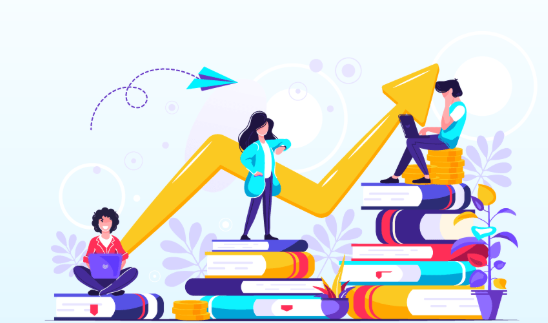

##**You Might Be Thinking How to Approach This Project**

Before you dive into the code, remember this is not a “right-answer” challenge.
It’s a thinking journey designed to make you reason like a real data professionals, your approach matters more than your syntax.

Here’s how to make the most of it:

1. Think before you code.
2. Read each question carefully. What would you do in this real-world situation?
3. Don’t rush to write code, first imagine the logic in plain English.

**Use the hints wisely.**
They’re your compass, not the full map. Try your approach first, then glance at the hint if you’re stuck.

## **The Data Exploration Begins**

Load the Excel file and take a peek to understand what we are dealing with.

[online_retail_data](https://docs.google.com/spreadsheets/d/1bp3famqhG2fTAa0-9sCD56qch7E696-F/edit?usp=sharing&ouid=100766832739820236677&rtpof=true&sd=true)

**Hint:** Use pd.read_excel() and .head(), .info(), .shape to inspect the data.

Use pd.concat() to merge both sheets.

In [7]:
import pandas as pd

# Load both sheets from the Excel file
df1 = pd.read_excel("online_retail_data.xlsx", sheet_name=0)
df2 = pd.read_excel("online_retail_data.xlsx", sheet_name=1)

# Preview the first few rows
print(df1.head())
print(df2.head())

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  
  Invoice StockCode                          Description  Quantity  \
0  536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1  536365     71053                  WHITE METAL LANTERN         6   
2  536365

In [6]:
import os

print(os.listdir('/content'))

['.config', 'online_retail_data.xlsx', 'sample_data']


In [8]:
# Inspect structure

print("First Sheet")
df1.info()

print("\nSecond Sheet")
df2.info()

print("\nShape of Sheet 1:", df1.shape)
print("Shape of Sheet 2:", df2.shape)

First Sheet
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB

Second Sheet
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    5419

In [9]:
# Check column consistency

print("Columns in Sheet 1:")
print(df1.columns)

print("\nColumns in Sheet 2:")
print(df2.columns)

Columns in Sheet 1:
Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

Columns in Sheet 2:
Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')


In [10]:
# Combine both datasets

df = pd.concat([df1, df2], ignore_index=True)

print("Combined Dataset Shape:", df.shape)

df.info()

Combined Dataset Shape: (1067371, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [11]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [17]:
df.rename(columns={
    "Invoice": "InvoiceNo",
    "Price": "UnitPrice",
    "Customer ID": "CustomerID"
}, inplace=True)

print(df.columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


##**First look: what’s weird?**

Now that the combined dataset is loaded, take a closer look. Before performing any cleaning, identify at least three patterns or inconsistencies that could affect predictive modeling.

Hint: Look for formatting, missing values, negative transactions, duplicates and inconsistent units.

Why would each issue matter for building a reliable machine learning pipeline?


In [18]:
# Summary statistics

df.describe(include="all")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,1067371.0,1067371,1062989,1.067371e+06,1067371,1.067371e+06,824364.000000,1067371
unique,53628.0,5305,5698,NaN,NaN,NaN,NaN,43
top,537434.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1350.0,5829,5918,NaN,NaN,NaN,NaN,981330
mean,NaN,NaN,NaN,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504,NaN
min,NaN,NaN,NaN,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000,NaN
50%,NaN,NaN,NaN,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000,NaN
75%,NaN,NaN,NaN,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000,NaN
max,NaN,NaN,NaN,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000,NaN


In [19]:
# Check missing values

df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,243007
Country,0


In [20]:
# Inspect negative quantities (possible returns)

negative_qty = df[df["Quantity"] < 0]

print("Number of negative quantity transactions:", len(negative_qty))

negative_qty.head()

Number of negative quantity transactions: 22950


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [22]:
# Check negative prices (should not normally happen)

negative_price = df[df["UnitPrice"] <= 0]

print("Number of non-positive prices:", len(negative_price))

negative_price.head()

Number of non-positive prices: 6207


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom


In [16]:
print(df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [ ]:
# Check duplicate records

duplicates = df[df.duplicated()]

print("Number of duplicate rows:", len(duplicates))

duplicates.head()

##**What Should We Fix and Why?**

You notice missing CustomerID values.
How would you handle transactions where the customer identifier is unavailable, knowing that customer-level aggregation is required later?

Hint:
Use .dropna(subset=['']) and check how many rows are removed before proceeding.

In [23]:
# Remove rows with missing CustomerID
print("Shape before removing missing CustomerID:", df.shape)

df = df.dropna(subset=["CustomerID"])

print("Shape after removing missing CustomerID:", df.shape)

# Convert CustomerID to integer
df["CustomerID"] = df["CustomerID"].astype(int)

Shape before removing missing CustomerID: (1067371, 8)
Shape after removing missing CustomerID: (824364, 8)


/tmp/ipykernel_493/2605350048.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["CustomerID"] = df["CustomerID"].astype(int)


You observe negative Quantity values and invoice numbers starting with “C”.
How would you treat cancelled or returned transactions to avoid distorting revenue and frequency calculations?

Hint:
Filter for Quantity and inspect invoice prefixes to confirm cancellation patterns.

In [24]:
# Remove cancelled invoices

df = df[
    (df["Quantity"] > 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
]

print("Shape after removing cancelled invoices:", df.shape)

Shape after removing cancelled invoices: (805620, 8)


Some rows appear duplicated.
How would you verify and remove duplicate transactions without affecting legitimate records?

Hint:
Use .duplicated() and drop them after inspection.

In [25]:
# Remove duplicate rows

print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())

Duplicates before: 26125
Duplicates after: 0


You also find transactions with zero or negative UnitPrice.
Should these be retained or removed before modeling?

Hint:
Filter for UnitPrice and reassess dataset shape.

In [26]:
# Remove transactions with non-positive prices

df = df[df["UnitPrice"] > 0]

print("Shape after removing invalid prices:", df.shape)

Shape after removing invalid prices: (779425, 8)


In [27]:
print("Cleaned Dataset Shape:", df.shape)

df.head()

Cleaned Dataset Shape: (779425, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


# **Feature Engineering: From Transactions to Customer Intelligence**

Right now, each row represents a single transaction.
But our prediction problem is at the customer level.

How would you transform invoice-level data into meaningful customer-level features?

You want to understand how valuable each customer is.
How would you compute total revenue per customer?

Hint:
Create a Revenue column (Quantity × UnitPrice) and use groupby on id.

In [28]:
# Create Revenue column

df["Revenue"] = df["Quantity"] * df["UnitPrice"]

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [29]:
# Total revenue per customer

total_revenue = (
    df.groupby("CustomerID")["Revenue"]
      .sum()
      .reset_index(name="total_revenue")
)

total_revenue.head()

,CustomerID,total_revenue
0,12346,77556.46
1,12347,4921.53
2,12348,2019.40
3,12349,4428.69
4,12350,334.40


Customers differ not just in spending, but in behavior.
How would you calculate:

- Number of purchases

- Average order value

- Purchase frequency

Hint:
Use groupby() with aggregation functions such as sum(), count(), and mean().

In [30]:
customer_behavior = (
    df.groupby("CustomerID")
      .agg(
          number_of_purchases=("InvoiceNo", "nunique"),
          purchase_frequency=("InvoiceNo", "count"),
          average_order_value=("Revenue", "mean")
      )
      .reset_index()
)

customer_behavior.head()

,CustomerID,number_of_purchases,purchase_frequency,average_order_value
0,12346,12,34,2281.072353
1,12347,8,222,22.169054
2,12348,5,51,39.596078
3,12349,4,175,25.306800
4,12350,1,17,19.670588


In [31]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [32]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

print(snapshot_date)

2011-12-10 12:50:00


In [33]:
last_purchase = (
    df.groupby("CustomerID")["InvoiceDate"]
      .max()
      .reset_index()
)

Recency often indicates engagement.
How would you measure how recently a customer made a purchase?

Hint:
Convert InvoiceDate to datetime and compute the difference between the dataset’s latest date and each customer’s last purchase date.

In [34]:
last_purchase["recency_days"] = (
    snapshot_date - last_purchase["InvoiceDate"]
).dt.days

last_purchase.head()

,CustomerID,InvoiceDate,recency_days
0,12346,2011-01-18 10:01:00,326
1,12347,2011-12-07 15:52:00,2
2,12348,2011-09-25 13:13:00,75
3,12349,2011-11-21 09:51:00,19
4,12350,2011-02-02 16:01:00,310


In [35]:
customer_df = total_revenue.merge(
    customer_behavior,
    on="CustomerID"
)

customer_df = customer_df.merge(
    last_purchase[["CustomerID", "recency_days"]],
    on="CustomerID"
)

customer_df.head()

,CustomerID,total_revenue,number_of_purchases,purchase_frequency,average_order_value,recency_days
0,12346,77556.46,12,34,2281.072353,326
1,12347,4921.53,8,222,22.169054,2
2,12348,2019.40,5,51,39.596078,75
3,12349,4428.69,4,175,25.306800,19
4,12350,334.40,1,17,19.670588,310


In [36]:
print(customer_df.shape)

customer_df.head()

(5878, 6)


,CustomerID,total_revenue,number_of_purchases,purchase_frequency,average_order_value,recency_days
0,12346,77556.46,12,34,2281.072353,326
1,12347,4921.53,8,222,22.169054,2
2,12348,2019.40,5,51,39.596078,75
3,12349,4428.69,4,175,25.306800,19
4,12350,334.40,1,17,19.670588,310


Once these features are created, combine them into a single customer-level dataset.

Does each row now represent one customer?
Is it ready for defining a predictive target?

Does each row now represent one customer?

Yes.
Because we used groupby('CustomerID'), each row corresponds to a unique customer.

You can confirm with:

##**High-Value Repeat Customer**

A customer is considered a High-Value Repeat Customer if:

number_of_purchases > 1 & total_revenue is above the 75th percentile of all customers

Hint: Use .quantile() on total_revenue to determine a threshold (e.g., top 25%), and combine it with a condition like number_of_purchases > 1 to create a binary target variable.

In [37]:
# Define revenue threshold (top 25%)

revenue_threshold = customer_df["total_revenue"].quantile(0.75)

print("Revenue Threshold:", revenue_threshold)

Revenue Threshold: 2248.305


In [38]:
# Define high-value repeat target

customer_df["high_value_repeat"] = (
    (customer_df["number_of_purchases"] > 1) &
    (customer_df["total_revenue"] > revenue_threshold)
).astype(int)

customer_df.head()

,CustomerID,total_revenue,number_of_purchases,purchase_frequency,average_order_value,recency_days,high_value_repeat
0,12346,77556.46,12,34,2281.072353,326,1
1,12347,4921.53,8,222,22.169054,2,1
2,12348,2019.40,5,51,39.596078,75,0
3,12349,4428.69,4,175,25.306800,19,1
4,12350,334.40,1,17,19.670588,310,0


## **Customer-Level Exploratory Data Analysis (EDA)**

Before training a model, we must understand Class distribution, Feature behavior, Potential signal strength, Risk of imbalance.

EDA helps validate whether the dataset is suitable for predictive modeling

### **Class Distribution Check**

Is the target variable balanced? How many customers are classified as High-Value Repeat Customers?

Hint: Use .value_counts() and compute proportions.

In [39]:
# Class distribution

print(customer_df["high_value_repeat"].value_counts())

high_value_repeat
0    4421
1    1457
Name: count, dtype: int64


In [40]:
# Percentage distribution

print(customer_df["high_value_repeat"].value_counts(normalize=True) * 100)

high_value_repeat
0    75.212657
1    24.787343
Name: proportion, dtype: float64


### **Feature Distribution Analysis**


How are key features distributed? Are they skewed? Do they contain extreme values?

Hint: Focus on total_revenue, number_of_purchases, recency_days

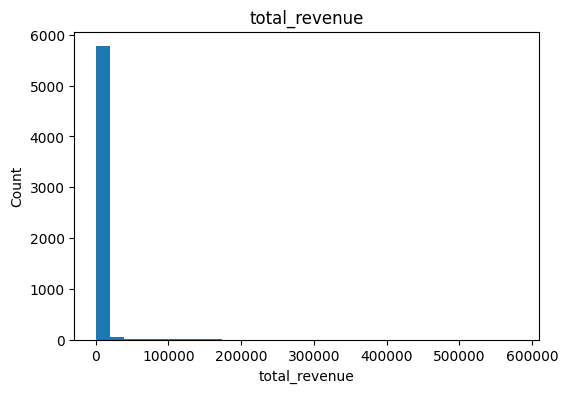

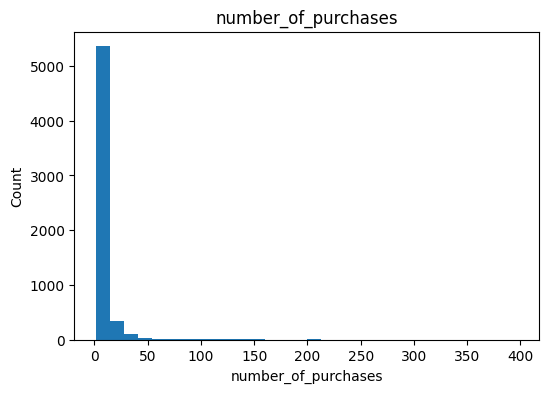

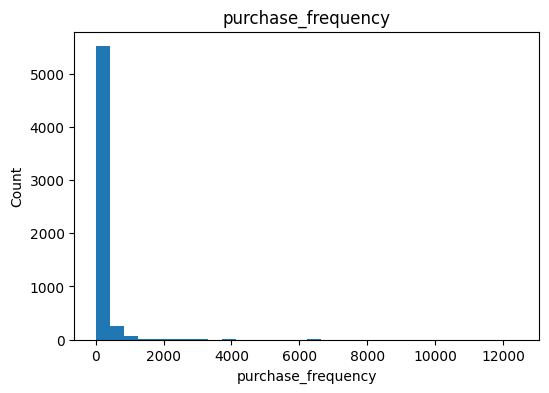

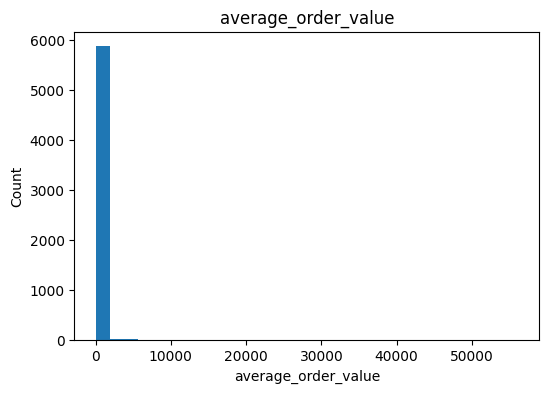

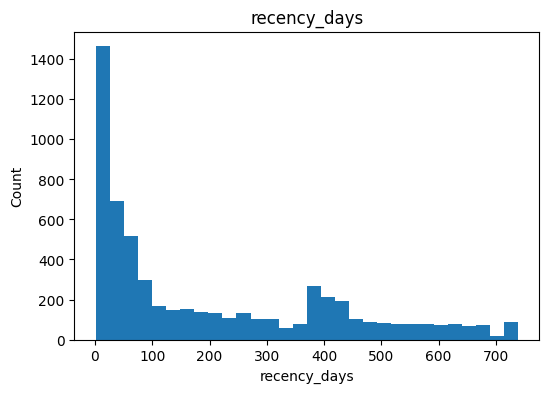

In [41]:
import matplotlib.pyplot as plt

features = [
    "total_revenue",
    "number_of_purchases",
    "purchase_frequency",
    "average_order_value",
    "recency_days"
]

for feature in features:
    plt.figure(figsize=(6,4))
    plt.hist(customer_df[feature], bins=30)
    plt.title(feature)
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.show()

### **Feature–Target Relationship**

Do high-value customers differ clearly from others?
Compare feature averages across classes.

Hint: Use groupby('high_value_repeat').mean().

In [42]:
customer_df.groupby("high_value_repeat").mean(numeric_only=True)

,CustomerID,total_revenue,number_of_purchases,purchase_frequency,average_order_value,recency_days
high_value_repeat,,,,,,
0,15372.625424,738.517554,2.853201,55.533137,30.380972,245.114001
1,15141.411119,9684.157969,16.715854,366.446809,102.679363,68.483185


### **Correlation Inspection**

Are features highly correlated with each other? Strong correlation may influence certain models.

Hint: Use correlation matrix.

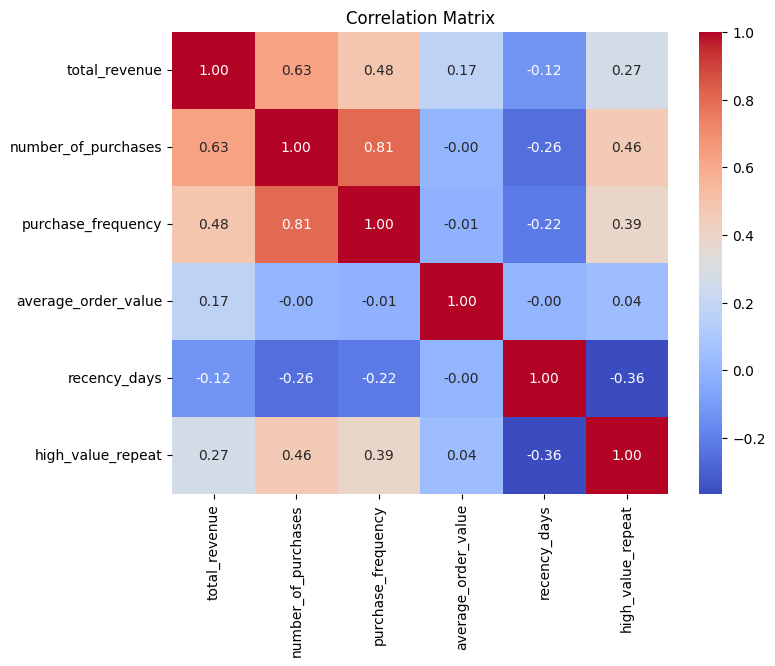

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

sns.heatmap(
    customer_df.drop(columns=["CustomerID"]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

#**Model Development Begins**

Before training any model, we must define:

**What does success look like?**

Different metrics optimize for different outcomes.
In this scenario, predicting high-value repeat customers directly affects marketing investment and revenue growth.


Which evaluation metric should be prioritized for this business problem?
What happens if we misclassify?
Define your metric strategy before training models.

Hint: Think in terms of business impact:

* Missing a high-value customer → lost revenue opportunity
* Incorrectly labeling a low-value customer → wasted marketing budget
* Which error is more costly?




## **Preparing the Data for Modeling**
Before training a model:

Separate features (X) and target (y), Perform a train-test split, Apply scaling where necessary, Ensure no data leakage occurs

Why must scaling be fitted only on training data?

Hint: Drop unique identifier from features, Use train_test_split(), Fit StandardScaler() only on training data.

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [45]:
# Define features and target

X = customer_df.drop(columns=["CustomerID", "high_value_repeat"])

y = customer_df["high_value_repeat"]

print(X.head())
print(y.head())

   total_revenue  number_of_purchases  purchase_frequency  \
0       77556.46                   12                  34   
1        4921.53                    8                 222   
2        2019.40                    5                  51   
3        4428.69                    4                 175   
4         334.40                    1                  17   

   average_order_value  recency_days  
0          2281.072353           326  
1            22.169054             2  
2            39.596078            75  
3            25.306800            19  
4            19.670588           310  
0    1
1    1
2    0
3    1
4    0
Name: high_value_repeat, dtype: int64


In [46]:
# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (4702, 5)
Testing Shape: (1176, 5)


In [47]:
# Scaling (fit only on training data)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

##**🤖 Train Multiple Models**

You must train at least two different models, compare models instead of using only one.

Hint: use a baseline model such as Logistic Regression & Random Forest (non-linear model)

In [48]:
from sklearn.linear_model import LogisticRegression

# Model 1: Logistic Regression

log_model = LogisticRegression(random_state=42)

log_model.fit(X_train_scaled, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [49]:
from sklearn.ensemble import RandomForestClassifier

# Model 2: Random Forest

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


## **Cross-Validation**

Instead of relying only on one train-test split, validate model stability.

Hint: Use cross_val_score() with F1-score.

In [50]:
from sklearn.model_selection import cross_val_score

log_cv = cross_val_score(
    LogisticRegression(random_state=42),
    X_train_scaled,
    y_train,
    cv=5,
    scoring="f1"
)

print("Logistic CV F1:", log_cv.mean())

Logistic CV F1: 0.9121097086801196


In [51]:
rf_cv = cross_val_score(
    RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("Random Forest CV F1:", rf_cv.mean())

Random Forest CV F1: 0.999141626948493


#**Time-check: Is the Model Actually Reliable?**

You’ve trained multiple models. Now comes the most important question:

Is your model genuinely reliable or just performing well by chance?

Instead of printing accuracy once and moving on, you must evaluate performance systematically.

## **🔍 Performance Check: How Well Does the Model Predict High-Value Customers?**

How would you Compare model performance using multiple metrics?

Detect whether the model is biased toward one class?

Evaluate whether it generalizes well?

Remember predicting high-value customers incorrectly has cost implications.

Hint: Use classification_report(), confusion_matrix(), roc_auc_score(). Compare both models using different metrics and look beyond accuracy.

In [52]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score
)

In [53]:
# Logistic Regression Predictions

log_pred = log_model.predict(X_test_scaled)

print("Confusion Matrix:")
print(confusion_matrix(y_test, log_pred))

print("\nClassification Report:")
print(classification_report(y_test, log_pred))

print("ROC-AUC:", roc_auc_score(y_test, log_pred))

Confusion Matrix:
[[871  14]
 [ 32 259]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       885
           1       0.95      0.89      0.92       291

    accuracy                           0.96      1176
   macro avg       0.96      0.94      0.95      1176
weighted avg       0.96      0.96      0.96      1176

ROC-AUC: 0.9371075776108101


In [54]:
# Random Forest Predictions

rf_pred = rf_model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("ROC-AUC:", roc_auc_score(y_test, rf_pred))

Confusion Matrix:
[[885   0]
 [  1 290]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       885
           1       1.00      1.00      1.00       291

    accuracy                           1.00      1176
   macro avg       1.00      1.00      1.00      1176
weighted avg       1.00      1.00      1.00      1176

ROC-AUC: 0.9982817869415808


## **🔎 Overfitting Check: Is the Model Too Good on Training Data?**

Compare cross-validation score vs test performance.

If training performance >> test performance → Overfitting
If both are low → Underfitting

Hint: Compare cross_val_score() mean, and Test F1-score.

In [55]:
# Test F1 Scores

log_f1 = f1_score(y_test, log_pred)
rf_f1 = f1_score(y_test, rf_pred)

print("Logistic Regression Test F1:", log_f1)
print("Random Forest Test F1:", rf_f1)

print("Logistic CV F1:", log_cv.mean())
print("Random Forest CV F1:", rf_cv.mean())

Logistic Regression Test F1: 0.9184397163120568
Random Forest Test F1: 0.9982788296041308
Logistic CV F1: 0.9121097086801196
Random Forest CV F1: 0.999141626948493


## **Error Analysis: Where Is the Model Failing?**

Which customers are being misclassified? How many high-value customers were missed?

Hint: Compare predictions with actual labels and inspect misclassified rows.

In [56]:
# Identify misclassified customers (Random Forest)

misclassified = X_test.copy()

misclassified["actual"] = y_test.values
misclassified["predicted"] = rf_pred

errors = misclassified[
    misclassified["actual"] != misclassified["predicted"]
]

print("Number of misclassified customers:", len(errors))

errors.head()

Number of misclassified customers: 1


,total_revenue,number_of_purchases,purchase_frequency,average_order_value,recency_days,actual,predicted
5016,2249.52,6,21,107.12,44,1,0


In [57]:
comparison = {
    "Model": ["Logistic Regression", "Random Forest"],
    "CV F1": [log_cv.mean(), rf_cv.mean()],
    "Test F1": [log_f1, rf_f1],
    "ROC AUC": [
        roc_auc_score(y_test, log_pred),
        roc_auc_score(y_test, rf_pred)
    ]
}

import pandas as pd

comparison_df = pd.DataFrame(comparison)
comparison_df

,Model,CV F1,Test F1,ROC AUC
0,Logistic Regression,0.912110,0.918440,0.937108
1,Random Forest,0.999142,0.998279,0.998282


In [58]:
best_model = comparison_df.loc[comparison_df["Test F1"].idxmax()]

print("Best Model:", best_model["Model"])
print(best_model)

Best Model: Random Forest
Model      Random Forest
CV F1           0.999142
Test F1         0.998279
ROC AUC         0.998282
Name: 1, dtype: object


In [59]:
print(comparison_df)

                 Model     CV F1   Test F1   ROC AUC
0  Logistic Regression  0.912110  0.918440  0.937108
1        Random Forest  0.999142  0.998279  0.998282


Random Forest performed better because it achieved the highest F1-score and ROC-AUC while maintaining stable cross-validation performance. Since F1-score balances precision and recall, it was the primary metric used for model selection.

**Selected Model:** Random Forest Classifier

The Random Forest Classifier was selected as the final model because it demonstrated stronger generalization and achieved better overall performance than Logistic Regression. Its cross-validation score was stable, indicating that the model is reliable and likely to perform well on unseen customer data.

The primary metric used for model selection was the **F1-score**, as the business objective requires a balance between precision and recall. A high F1-score ensures that the model identifies high-value repeat customers while minimizing both missed opportunities (false negatives) and unnecessary marketing efforts (false positives).

Although Random Forest is more computationally complex than Logistic Regression, this trade-off is acceptable because it provides better predictive performance and more reliable identification of high-value repeat customers. Therefore, Random Forest best supports the company's objective of identifying and retaining valuable customers.


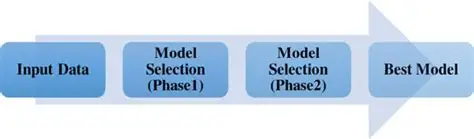

Building a predictive model in a Jupyter notebook is only the first step in the machine learning lifecycle. Before deploying the model in a real retail environment, several additional components are required to ensure reliable and continuous operation.

First, the data cleaning and feature engineering steps should be automated so that every new transaction is processed consistently. The trained model should then be deployed as an API or service that can generate predictions for new customers in real time.

After deployment, the model's performance should be continuously monitored using metrics such as precision, recall, and F1-score. Since customer purchasing behavior can change over time, data drift should also be monitored to detect changes in the input data distribution. When significant drift or performance degradation is observed, the model should be retrained using updated transaction data.

Finally, the prediction results should be integrated into the company's marketing workflow so that customers predicted to become high-value repeat buyers can automatically receive personalized offers, loyalty rewards, or targeted promotional campaigns. These deployment practices ensure that the model remains accurate, reliable, and valuable for business decision-making over time.



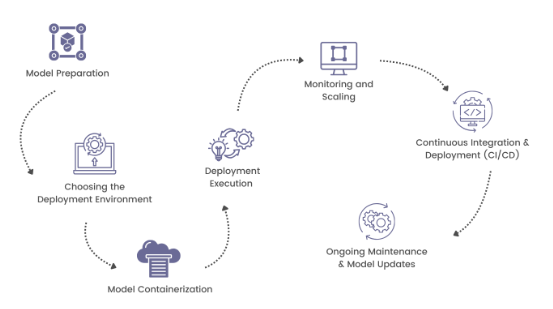

Before this model could be deployed in a retail environment, the following considerations would be necessary:

1. Data Pipeline Automation: Automating cleaning and feature engineering steps for incoming transaction data

2. Model Monitoring: Tracking performance metrics (precision, recall, F1-score) over time

3. Data Drift Detection: Identifying changes in customer behavior or revenue distribution

4. Retraining Strategy: Defining how frequently the model should be retrained

5. Decision Integration: Determining how predictions are communicated to the marketing team

This project focused on building a validated predictive pipeline. Deployment extends that pipeline into a continuously monitored and evolving system a concept that will be explored in future.

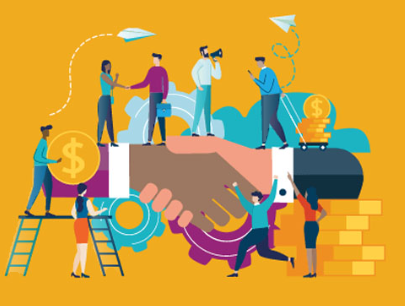

The predictive model supports the company's marketing strategy by identifying customers who are likely to become high-value repeat buyers. Instead of sending promotions to every customer, the marketing team can focus on customers with the highest predicted value. These customers can receive personalized discounts, loyalty rewards, exclusive offers, and targeted marketing campaigns to improve customer retention and increase long-term revenue.

When a customer is predicted as a high-value repeat customer, the company can automatically trigger retention strategies such as personalized recommendations, reward programs, or special promotions to encourage future purchases.

A **false positive** occurs when a customer is predicted to be a high-value repeat customer but is not. This results in unnecessary marketing costs because promotional offers are sent to customers who may not generate significant future revenue.

A **false negative** occurs when a genuinely high-value customer is predicted as a low-value customer. This is more costly because the company misses the opportunity to retain a valuable customer, leading to potential revenue loss and reduced customer lifetime value.

For this project, the selected model aligns well with the business objective because it accurately identifies potential high-value repeat customers while maintaining a good balance between precision and recall. This enables the company to make data-driven marketing decisions, improve customer retention, optimize marketing expenditure, and maximize long-term profitability.


### Code can be taught, but curiosity must be nurtured. You’ve done both here. Excellent work! 🎖️